# 01 - EDA of CarDD

Thin orchestration notebook: all logic lives in `cardd.data.stats`, `cardd.viz.eda` and `cardd.viz.overlay`.
Requires the raw COCO data in `data/raw/CarDD` (`annotations/instances_{train,val,test}2017.json`) and, for overlays, the converted YOLO-seg dataset from `python -m cardd.data.convert`.

In [1]:
from pathlib import Path

import yaml
from IPython.display import Image, Markdown, display

from cardd.data.stats import class_distribution, imbalance_ratio, load_images, load_instances
from cardd.viz.eda import plot_area_distribution, plot_class_distribution
from cardd.viz.overlay import save_random_overlays

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
COCO_DIR = REPO_ROOT / "data" / "raw" / "CarDD"
FIG_DIR = REPO_ROOT / "docs" / "figures"
LANG = "pl"

In [2]:
instances = load_instances(COCO_DIR)
images = load_images(COCO_DIR)
dist = class_distribution(instances)
display(images.groupby("split").size().rename("n_images").to_frame())
display(dist.pivot(index="class_name", columns="split", values="n_instances"))

,n_images
split,
test,374
train,2816
val,810


split,test,train,val
class_name,,,
crack,70,651,177
dent,236,1806,501
glass_shatter,71,475,135
lamp_broken,69,494,141
scratch,307,2560,728


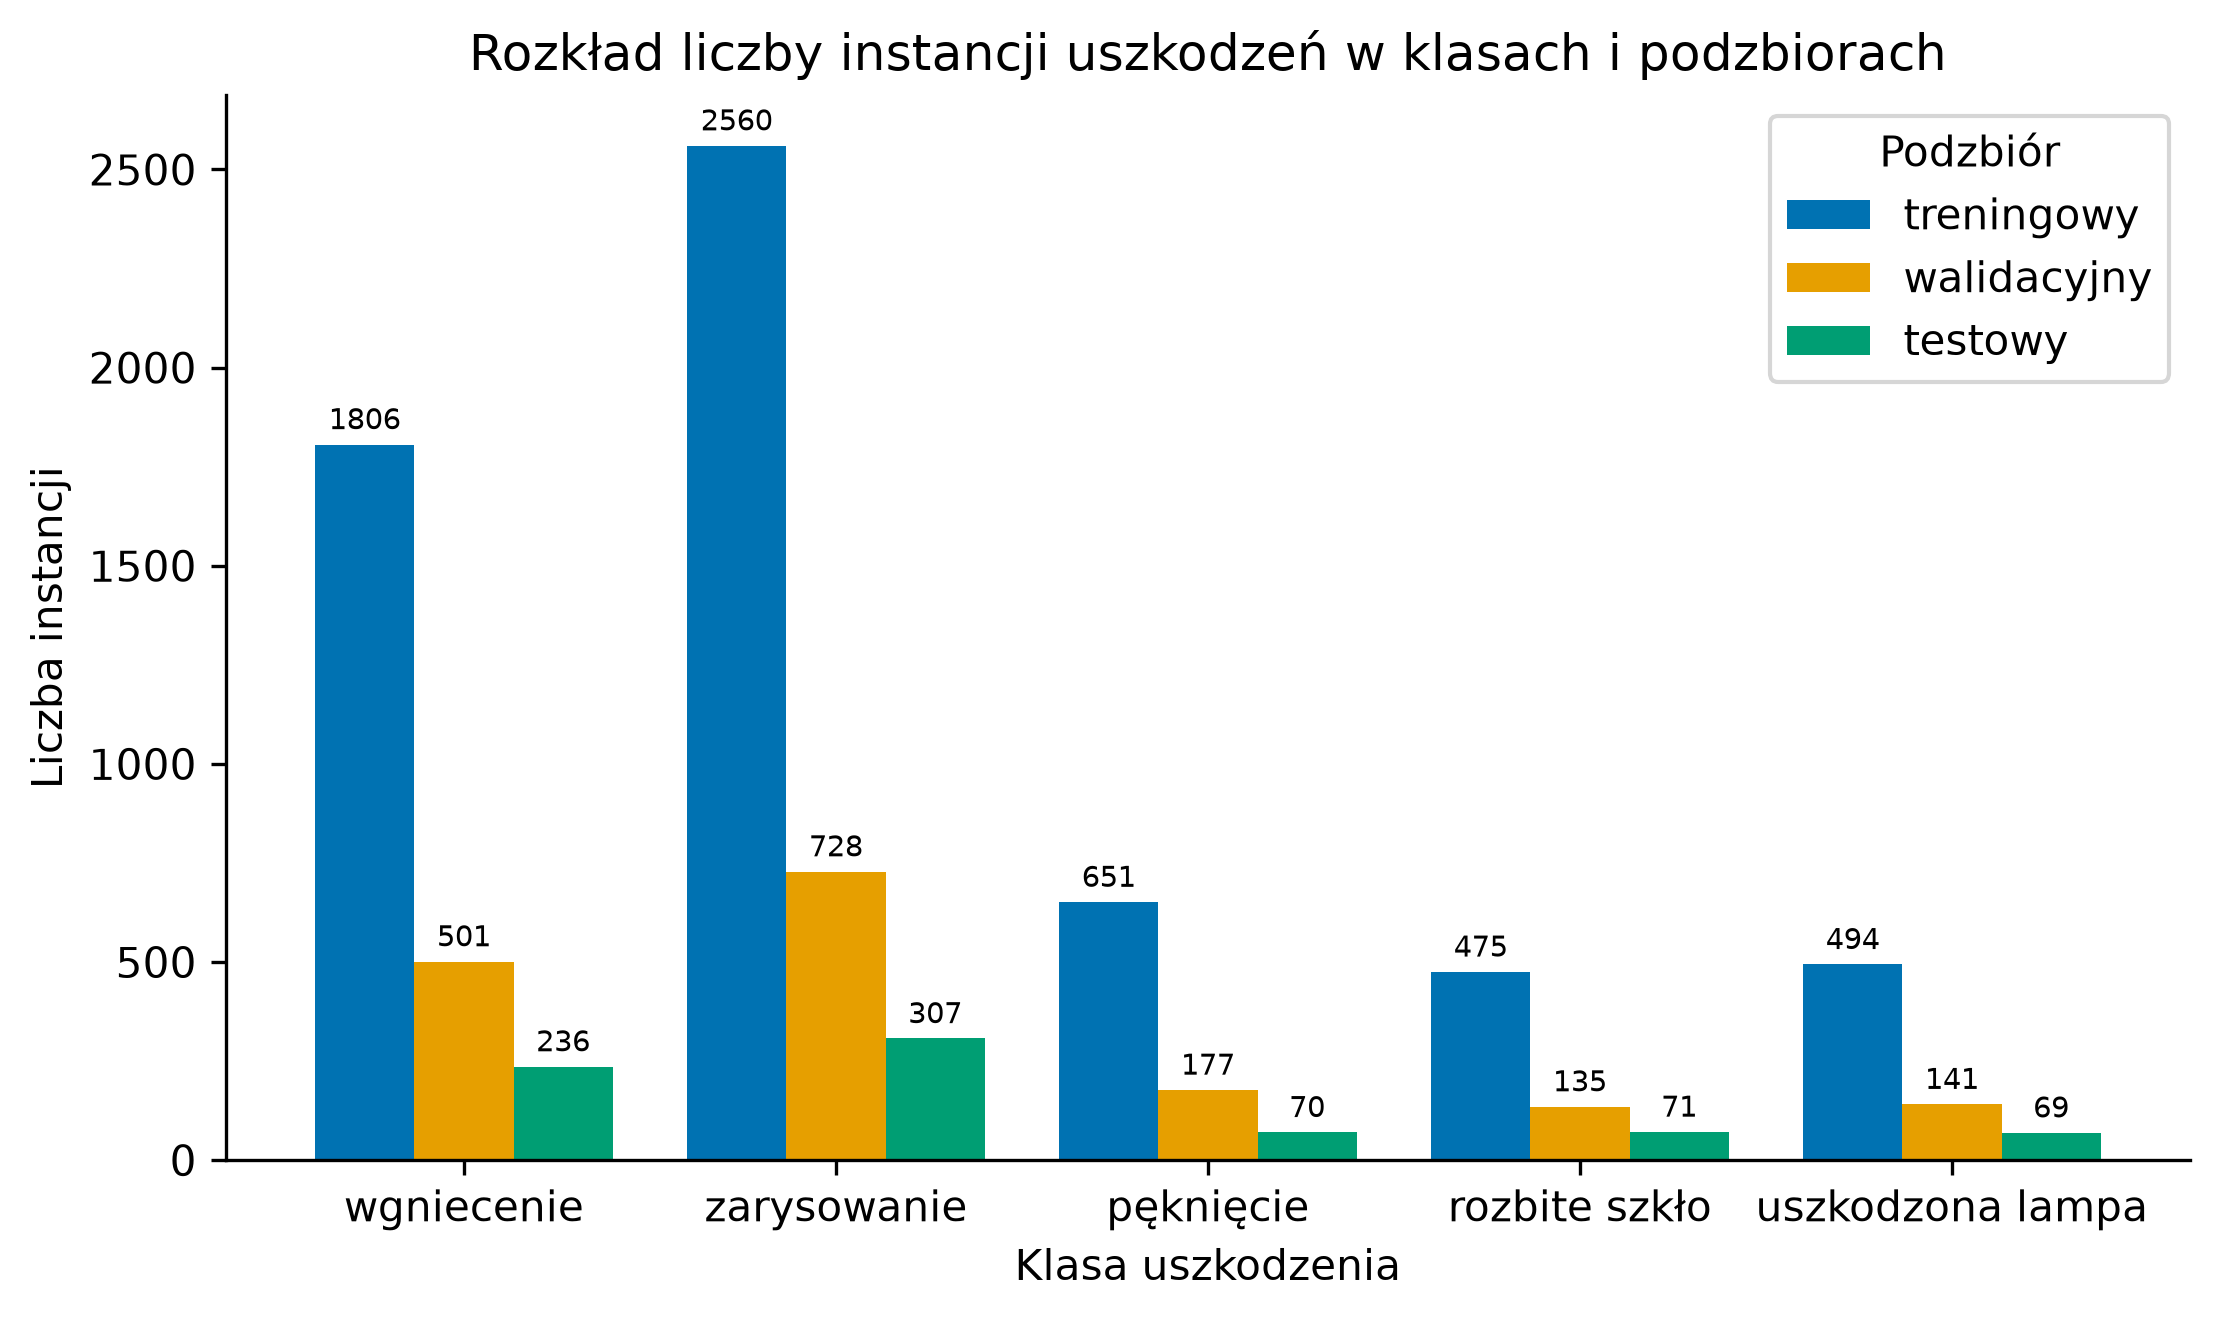

In [3]:
out = FIG_DIR / f"class_distribution_{LANG}.png"
plot_class_distribution(dist, lang=LANG, out=out)
display(Image(filename=out))

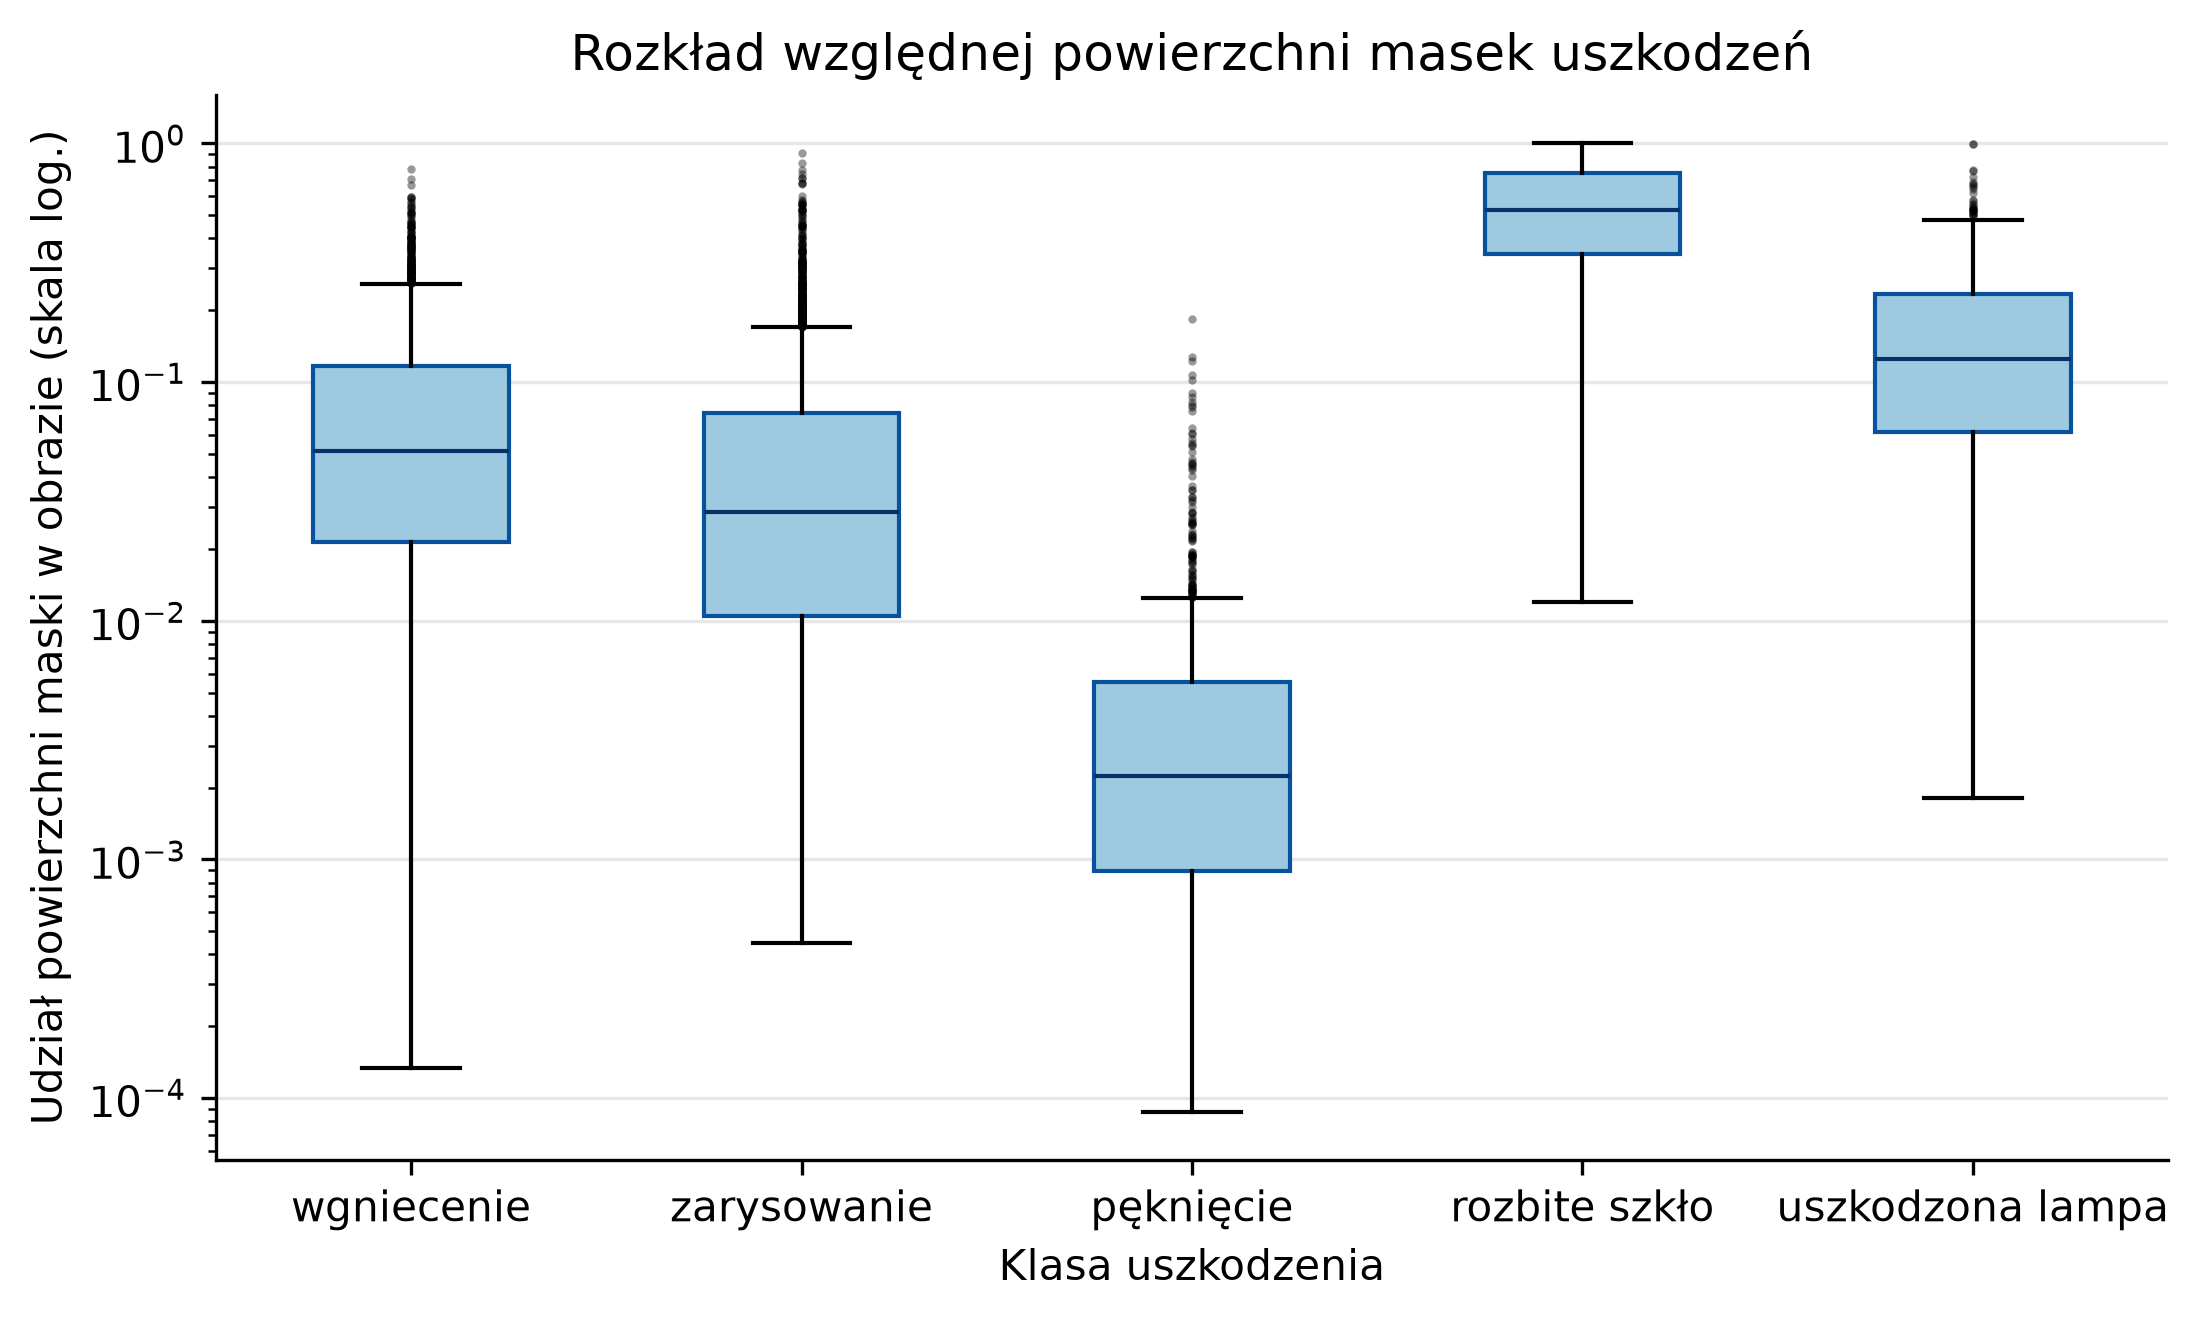

In [4]:
out = FIG_DIR / f"area_distribution_{LANG}.png"
plot_area_distribution(instances, lang=LANG, out=out)
display(Image(filename=out))

In [5]:
train_counts = dist[dist["split"] == "train"].set_index("class_name")["n_instances"]
display(
    Markdown(
        f"**Imbalance ratio (train, max/min instances): {imbalance_ratio(instances):.2f}**\n\n"
        + "\n".join(f"- `{name}`: {n}" for name, n in train_counts.items())
    )
)

**Imbalance ratio (train, max/min instances): 5.39**

- `dent`: 1806
- `scratch`: 2560
- `crack`: 651
- `glass_shatter`: 475
- `lamp_broken`: 494

## Visual QA of the converter (issue #3)

Random, seeded overlays of converted YOLO-seg labels, saved to `docs/figures/overlays/`.

In [6]:
cfg = yaml.safe_load((REPO_ROOT / "configs" / "data.yaml").read_text(encoding="utf-8"))
yolo_root = REPO_ROOT / cfg["path"]
if (yolo_root / "images" / "train").exists():
    save_random_overlays(
        yolo_root / "images" / "train",
        yolo_root / "labels" / "train",
        n=30,
        seed=42,
        out_dir=FIG_DIR / "overlays",
    )
else:
    print(f"Converted dataset not found at {yolo_root}; run `python -m cardd.data.convert` first.")